# 目標占有率に対する H₂ と末端割合

研究報告の補足表を、目標占有率 0.10〜0.70（0.01 刻み）の試料別データで描き直す。初期設定は **L=128、各条件100試料、平均 ± SD**。入力の6列をノートブックに同梱したので、Colabで「すべてのセルを実行」すれば、CSVのアップロードなしで作図できる。設定セルで L と誤差棒の種類を変えられる。

## 指標の定義

| 量 | 試料ごとの式 | 何を測るか |
|---|---|---|
| $H_2$ | ちょうど2本の結合を共有する分子ペア数 | 1試料あたりにいくつできるか |
| $q_{\mathrm{bonded}}$ | $4H_2/(2E)=2H_2/E$ | 結合済み末端のうち H₂ に使われた割合 |
| $q_{\mathrm{all}}$ | $4H_2/(4N)=H_2/N$ | 未結合も含む全末端のうち H₂ に使われた割合 |
| $p$ | $2E/(4N)=E/(2N)$ | 全末端のうち結合済みの割合 |

$N$ は分子数、$E$ は多重結合も1本ずつ数えた総結合数。1本の結合は末端2個を使い、H₂は2本で末端4個を使う。1分子は末端4個を持つ。試料ごとに $q_{\mathrm{all}}=p\,q_{\mathrm{bonded}}$ が成り立つ。図では各試料で量を計算してから条件ごとに試料を等重みで平均する。SDは試料間の標準偏差（ddof=1）。SEは SD を有効試料数の平方根で割った値。

横軸は生成条件の目標占有率 $\phi_{\mathrm{target}}$。先生の資料での実占有率 $\phi=mN/L^3$ は、配置された分子数から決まる。図の割合は最大クラスタも含めた系全体について集計する。

## 図の読み方と参照資料

H₂の個数と、結合済み末端の中でH₂が占める比重を分けて見る。全末端に対する割合には、末端結合率 $p$ の変化も反映される。この図は占有率に沿った比較であり、H₂を生成できる条件と制限する条件で最大連結成分を比較すれば、成長への影響を別に検証できる。

- 水高将吾「Tetra-PEG型SAWネットワークのゲル化転移」（2026年7月22日、ERATO公開シンポジウム）PDF 5・8・12ページ。$\phi$ と $p$ の区別、末端結合率と局所構造の関係を今回の軸の設計に使用。
- [Sakai et al., Polymer Journal 48, 629–634 (2016)](https://doi.org/10.1038/pj2015124)。濃度と反応転化率を分けて比較する際の参照。今回の格子占有率はモデル内の量として扱う。


In [1]:
L = 128  # 32, 64, 128
ERROR_BAR = "SD"  # "SD" または "SE"
DOWNLOAD_ZIP = False  # True にすると PNG・SVG・CSV をまとめてダウンロード


In [2]:
import base64
import gzip
import hashlib
from io import BytesIO

import pandas as pd

# 出典: 183条件 × 100試料の samples.csv から抽出した6列。
# 元 CSV の SHA-256: 759674a0d77505d3c3580f967e6e814d9e12e28373993fae25d173a8ec126af3
data = gzip.decompress(base64.b64decode("..."))
assert hashlib.sha256(data).hexdigest() == "4ed5da6a974c42bc47bb860a4b8f045abc26a92676b6ac2051da7edc322c62f5"
samples = pd.read_csv(BytesIO(data))


In [3]:
import numpy as np

if L not in (32, 64, 128) or ERROR_BAR not in ("SD", "SE"):
    raise ValueError("L は 32・64・128、誤差棒は SD または SE を指定してください。")

trial = samples.loc[samples["L"].eq(L)].copy()
counts = trial.groupby("target_phi").size()
if list(counts.index) != [i / 100 for i in range(10, 71)] or not counts.eq(100).all():
    raise ValueError("目標占有率61条件・各100試料を確認してください。")
if trial["case_id"].duplicated().any():
    raise ValueError("試料IDが重複しています。")

N, E, H2 = trial["N"], trial["bonds"], trial["H2"]
if not ((N > 0) & (H2 >= 0) & (2 * H2 <= E) & (E <= 2 * N)).all():
    raise ValueError("分子数・結合数・H₂数の関係を確認してください。")

# 百分率に変換してから条件別に集計。E=0 での結合済み末端割合は欠測。
trial["bonded_pct"] = 100 * (2 * H2 / E.where(E > 0))
trial["all_pct"] = 100 * H2 / N
trial["p_pct"] = 100 * E / (2 * N)
has_bonds = E.gt(0)
np.testing.assert_allclose(
    trial.loc[has_bonds, "all_pct"],
    (trial["p_pct"] * trial["bonded_pct"] / 100).loc[has_bonds],
)
metrics = ["H2", "bonded_pct", "all_pct", "p_pct"]
summary = trial.groupby("target_phi")[metrics].agg(["mean", "std", "count", "sem"])
summary.columns = [f"{quantity}_{stat}" for quantity, stat in summary.columns]
summary.insert(0, "L", L)
display(summary.loc[[0.10, 0.40, 0.43, 0.50, 0.70],
                    ["H2_mean", "bonded_pct_mean", "all_pct_mean", "p_pct_mean"]].round(3))


,H2_mean,bonded_pct_mean,all_pct_mean,p_pct_mean
target_phi,,,,
0.10,199.30,15.439,1.996,12.923
0.40,1953.37,12.358,4.890,39.571
0.43,2157.55,12.092,5.024,41.550
0.50,2655.53,11.599,5.318,45.852
0.70,3990.99,10.232,5.709,55.796


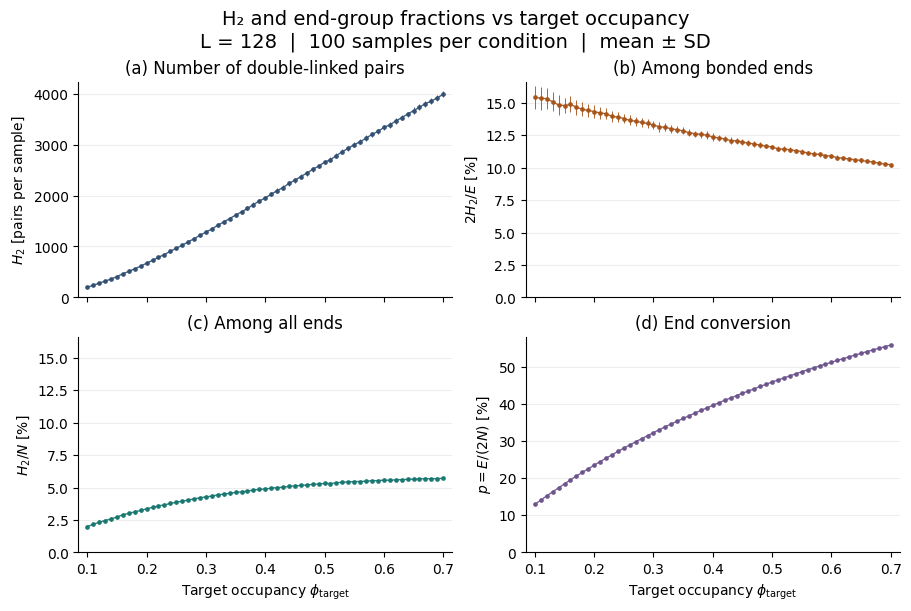

保存先: h2_endpoint_results/L128_SD


In [4]:
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt

output = Path("h2_endpoint_results") / f"L{L}_{ERROR_BAR}"
output.mkdir(parents=True, exist_ok=True)
figure_name = "H2_vs_target_phi"
panels = [
    ("H2", r"(a) Number of double-linked pairs", r"$H_2$ [pairs per sample]", "#304E72"),
    ("bonded_pct", "(b) Among bonded ends", r"$2H_2/E$ [%]", "#A75318"),
    ("all_pct", "(c) Among all ends", r"$H_2/N$ [%]", "#16766F"),
    ("p_pct", "(d) End conversion", r"$p=E/(2N)$ [%]", "#6B528B"),
]

fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, layout="constrained")
fig.suptitle(f"H₂ and end-group fractions vs target occupancy\n"
             f"L = {L}  |  100 samples per condition  |  mean ± {ERROR_BAR}",
             fontsize=14)
err = "std" if ERROR_BAR == "SD" else "sem"
for ax, (quantity, title, ylabel, color) in zip(axes.flat, panels):
    ax.errorbar(summary.index, summary[f"{quantity}_mean"],
                yerr=summary[f"{quantity}_{err}"], fmt="o-", color=color,
                ecolor=color, markersize=2.4, linewidth=1, elinewidth=.7, alpha=.9)
    ax.set(title=title, ylabel=ylabel, xlim=(.085, .715), ylim=(0, None))
    ax.set_xticks(np.arange(1, 8) / 10)
    ax.grid(axis="y", alpha=.22)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

# 二つの H₂ 末端割合に共通の縦軸を使う。
common_max = max(axes[0, 1].get_ylim()[1], axes[1, 0].get_ylim()[1])
for ax in (axes[0, 1], axes[1, 0]):
    ax.set_ylim(0, common_max)
for ax in axes[1]:
    ax.set_xlabel(r"Target occupancy $\phi_{\mathrm{target}}$")

files = [output / f"{figure_name}.{ext}" for ext in ("png", "svg", "csv")]
fig.savefig(files[0], dpi=240)
fig.savefig(files[1])
summary.to_csv(files[2])
plt.show()

if DOWNLOAD_ZIP:
    from google.colab import files as colab_files
    archive = output / f"{figure_name}_L{L}_{ERROR_BAR}.zip"
    with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
        for path in files:
            bundle.write(path, arcname=path.name)
    colab_files.download(str(archive))
else:
    print("保存先:", output)
